# 04 Preprocessing

Cleaning, missing-value features and scaling for the sepsis early-prediction data, fitted on the train split only.

In [1]:
import json
from contextlib import contextmanager
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
from scipy.stats import skew
from tqdm.auto import tqdm

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid")
COLORS = {"septic": "#d1495b", "non_septic": "#2e86ab", "A": "#edae49", "B": "#6a994e"}


def find_root(start):
    for folder in [start, *start.parents]:
        if (folder / "dataset").is_dir():
            return folder
    raise FileNotFoundError(f"no folder containing 'dataset' found above {start}")


ROOT = find_root(Path.cwd().resolve())
PROC = ROOT / "data" / "processed"
TABLES = ROOT / "results" / "tables"
FIGS = ROOT / "results" / "figures"
for folder in (PROC, TABLES, FIGS):
    folder.mkdir(parents=True, exist_ok=True)

SUMMARY = []
CHECKS = []


def log(text=""):
    print(text)
    SUMMARY.append(str(text))


def check(label, ok, detail=""):
    ok = bool(ok)
    CHECKS.append((label, ok))
    log(f"[{'PASS' if ok else 'FAIL'}] {label}" + (f" | {detail}" if detail else ""))


@contextmanager
def guarded(label):
    # a crash inside a check block is reported as a failed check and the notebook goes on
    try:
        yield
    except Exception as exc:
        check(label, False, f"error: {exc!r}")


with open(PROC / "column_groups.json") as f:
    groups = json.load(f)
VITALS, LABS, STATIC = groups["vitals"], groups["labs"], groups["static"]
TARGET = groups["target"][0] if isinstance(groups["target"], list) else groups["target"]

VALUE_COLS = VITALS + LABS
TSL_CAP = 72
CLIP_Q = (0.001, 0.999)
SKEW_LIMIT = 3
CHUNK_PATIENTS = 5000

# (low, high, low bound inclusive)
HARD_LIMITS = {"FiO2": (0.0, 1.0, False), "Temp": (25.0, 45.0, True)}

STD_COLS = VALUE_COLS + ["Age", "HospAdmTime", "ICULOS"]
ID_COLS = ["patient_id", "hospital", "hour", "split"]
MASK_COLS = [f"{c}_m" for c in VALUE_COLS]
TSL_COLS = [f"{c}_tsl" for c in VALUE_COLS]
STATIC_OUT = ["Age", "Gender", "unit_1", "unit_2", "unit_unknown", "HospAdmTime", "ICULOS"]
OUT_COLS = ID_COLS + VALUE_COLS + MASK_COLS + TSL_COLS + STATIC_OUT + [TARGET]
FEATURE_COLS = [c for c in OUT_COLS if c not in ID_COLS + [TARGET]]

log(f"project root: {ROOT.name}")
check("34 value columns", len(VALUE_COLS) == 34, f"{len(VALUE_COLS)} columns")
check("output layout has 114 columns", len(OUT_COLS) == 114, f"{len(OUT_COLS)} columns")

project root: Sepsis_ml
[PASS] 34 value columns | 34 columns
[PASS] output layout has 114 columns | 114 columns


/Users/harnoorkaur/Downloads/Sepsis_ml/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load



In [2]:
master = pd.read_parquet(PROC / "sepsis_master.parquet")
splits = pd.read_csv(PROC / "patient_splits.csv", dtype={"patient_id": str, "hospital": str})

split_of = splits.set_index("patient_id")["split"]
master["split"] = pd.Categorical(master["patient_id"].map(split_of), categories=["train", "val", "test"])

log(f"master shape (with split column): {master.shape}")
log(f"master memory: {master.memory_usage(deep=True).sum() / 1e6:.0f} MB")

EXPECTED_PATIENTS = {"train": 28235, "val": 6050, "test": 6051}
EXPECTED_ROWS = {"train": 1085958, "val": 234037, "test": 232215}

check("master has 1,552,210 rows x 44 columns", master.shape[0] == 1552210 and master.shape[1] - 1 == 44, f"{master.shape[0]} x {master.shape[1] - 1}")
check("every row has a split", master["split"].notna().all(), f"{int(master['split'].isna().sum())} rows without split")
check("splits table has 40,336 patients", len(splits) == 40336 and splits["patient_id"].is_unique, f"{len(splits)} patients")
check("master patients match splits table", set(master["patient_id"].unique()) == set(splits["patient_id"]), "")

patients_per_split = master.groupby("split", observed=True)["patient_id"].nunique()
rows_per_split = master["split"].value_counts()
for s in ["train", "val", "test"]:
    check(f"{s} patients", patients_per_split[s] == EXPECTED_PATIENTS[s], f"{int(patients_per_split[s])} vs {EXPECTED_PATIENTS[s]}")
    check(f"{s} rows", rows_per_split[s] == EXPECTED_ROWS[s], f"{int(rows_per_split[s])} vs {EXPECTED_ROWS[s]}")

check("positive rows total 27,916", master[TARGET].sum() == 27916, f"{int(master[TARGET].sum())}")
check("septic patients 2,932", splits["ever_septic"].sum() == 2932, f"{int(splits['ever_septic'].sum())}")

hosp_codes = pd.factorize(master["hospital"], sort=True)[0]
pid_codes = pd.factorize(master["patient_id"], sort=True)[0]
order = np.lexsort((master["hour"].to_numpy(), pid_codes, hosp_codes))
check("rows sorted by hospital, patient_id, hour", np.array_equal(order, np.arange(len(master))), "")
check("hour is the row position within each patient", np.array_equal(master["hour"].to_numpy(), master.groupby("patient_id").cumcount().to_numpy()), "")
rows_by_patient = master["patient_id"].value_counts()
check("rows per patient match n_rows in splits", (splits.set_index("patient_id")["n_rows"] == rows_by_patient.reindex(splits["patient_id"]).to_numpy()).all(), "")
del order, hosp_codes, pid_codes, rows_by_patient

miss = master[VALUE_COLS + ["Unit1", "Unit2", "HospAdmTime"]].isna().mean()
log(f"missing share: labs mean {miss[LABS].mean():.3f}, Glucose {miss['Glucose']:.3f}, EtCO2 {miss['EtCO2']:.3f}, Temp {miss['Temp']:.3f}, DBP {miss['DBP']:.3f}")
log("other vitals: " + ", ".join(f"{c} {miss[c]:.3f}" for c in ["HR", "O2Sat", "SBP", "MAP", "Resp"]))
check("lab missing share about 95%, Glucose below 90%", abs(miss[LABS].mean() - 0.95) < 0.01 and miss["Glucose"] < 0.90, "")
check("EtCO2 96%, Temp 66%, DBP 31% missing", abs(miss["EtCO2"] - 0.96) < 0.01 and abs(miss["Temp"] - 0.66) < 0.01 and abs(miss["DBP"] - 0.31) < 0.01, "")
check("other vitals 10 to 15% missing", all(0.08 < miss[c] < 0.17 for c in ["HR", "O2Sat", "SBP", "MAP", "Resp"]), "")
check("Unit1 and Unit2 missing together in 39.4% of rows", (master["Unit1"].isna() == master["Unit2"].isna()).all() and abs(miss["Unit1"] - 0.394) < 0.002, f"{miss['Unit1']:.4f}")
check("HospAdmTime missing in 8 rows", master["HospAdmTime"].isna().sum() == 8, f"{int(master['HospAdmTime'].isna().sum())} rows")

range_cols = ["HR", "O2Sat", "Temp", "Resp", "SBP", "MAP", "DBP", "FiO2", "AST", "WBC", "HospAdmTime"]
log(master[range_cols].agg(["min", "median", "max"]).T.round(2).to_string())
fio2 = master["FiO2"].dropna()
log(f"FiO2 values outside (0, 1]: {int(((fio2 <= 0) | (fio2 > 1)).sum())}")
del fio2

master shape (with split column): (1552210, 45)
master memory: 292 MB
[PASS] master has 1,552,210 rows x 44 columns | 1552210 x 44
[PASS] every row has a split | 0 rows without split
[PASS] splits table has 40,336 patients | 40336 patients
[PASS] master patients match splits table
[PASS] train patients | 28235 vs 28235
[PASS] train rows | 1085958 vs 1085958
[PASS] val patients | 6050 vs 6050
[PASS] val rows | 234037 vs 234037
[PASS] test patients | 6051 vs 6051
[PASS] test rows | 232215 vs 232215
[PASS] positive rows total 27,916 | 27916
[PASS] septic patients 2,932 | 2932
[PASS] rows sorted by hospital, patient_id, hour
[PASS] hour is the row position within each patient
[PASS] rows per patient match n_rows in splits
missing share: labs mean 0.948, Glucose 0.829, EtCO2 0.963, Temp 0.662, DBP 0.313
other vitals: HR 0.099, O2Sat 0.131, SBP 0.146, MAP 0.125, Resp 0.154
[PASS] lab missing share about 95%, Glucose below 90%
[PASS] EtCO2 96%, Temp 66%, DBP 31% missing
[PASS] other vitals 10

## Fit

Hard limits, clip bounds, medians and skewness, all from the train patients.

In [3]:
def hard_limit_valid(col, x):
    lo, hi, lo_inclusive = HARD_LIMITS[col]
    above = (x >= lo) if lo_inclusive else (x > lo)
    return above & (x <= hi)


def observed_values(x, col):
    # observed values of one column after the hard limits
    x = np.asarray(x, dtype=np.float64)
    if col in HARD_LIMITS:
        x = np.where(hard_limit_valid(col, x), x, np.nan)
    return x[~np.isnan(x)]


def fit_params(df):
    is_train = (df["split"] == "train").to_numpy()
    train = df.loc[is_train, ["patient_id"] + VALUE_COLS + ["Age", "HospAdmTime", "ICULOS"]]

    n_patients = train["patient_id"].nunique()
    log(f"fit uses {n_patients} train patients and {len(train)} train rows")
    check("fit uses 28,235 train patients", n_patients == 28235, f"{n_patients}")

    params = {
        "hard_limits": dict(HARD_LIMITS), "TSL_CAP": TSL_CAP, "CLIP_Q": CLIP_Q, "SKEW_LIMIT": SKEW_LIMIT,
        "n_train_patients": int(n_patients), "n_train_rows": int(len(train)),
        "n_set_nan_train": {}, "n_set_nan_all": {},
        "clip": {}, "median": {}, "n_clipped_low_train": {}, "n_clipped_high_train": {},
        "skew": {}, "log1p_flag": {},
    }

    for c in VALUE_COLS:
        for key, values in (("n_set_nan_train", train[c]), ("n_set_nan_all", df[c])):
            x = values.to_numpy(dtype=np.float64)
            removed = ~np.isnan(x) & ~hard_limit_valid(c, x) if c in HARD_LIMITS else np.zeros(len(x), dtype=bool)
            params[key][c] = int(removed.sum())

    clipped = {}
    for c in VALUE_COLS + ["HospAdmTime"]:
        x = observed_values(train[c].to_numpy(), c)
        lo, hi = np.quantile(x, CLIP_Q)
        lo, hi = float(np.float32(lo)), float(np.float32(hi))
        xc = np.clip(x, lo, hi)
        params["clip"][c] = (lo, hi)
        params["median"][c] = float(np.median(xc))
        params["n_clipped_low_train"][c] = int((x < lo).sum())
        params["n_clipped_high_train"][c] = int((x > hi).sum())
        clipped[c] = xc

    for c in STD_COLS:
        x = clipped[c] if c in clipped else observed_values(train[c].to_numpy(), c)
        sk = float(skew(x))
        params["skew"][c] = sk
        params["log1p_flag"][c] = bool(abs(sk) > SKEW_LIMIT)
    return params


params = fit_params(master)

flagged = [c for c in STD_COLS if params["log1p_flag"][c]]
log(f"columns with abs(skew) > {SKEW_LIMIT}: {len(flagged)} of {len(STD_COLS)}")
log(", ".join(f"{c} ({params['skew'][c]:.1f})" for c in flagged))
log(f"set to NaN by hard limits, train: {sum(params['n_set_nan_train'].values())}, all rows: {sum(params['n_set_nan_all'].values())}")
for c in HARD_LIMITS:
    log(f"  {c}: train {params['n_set_nan_train'][c]}, all rows {params['n_set_nan_all'][c]}")

fit uses 28235 train patients and 1085958 train rows
[PASS] fit uses 28,235 train patients | 28235
columns with abs(skew) > 3: 11 of 37
AST (6.2), Alkalinephos (5.4), Creatinine (4.1), Bilirubin_direct (3.8), Lactate (3.3), Bilirubin_total (5.2), TroponinI (5.2), PTT (3.5), WBC (3.1), HospAdmTime (-6.5), ICULOS (4.1)
set to NaN by hard limits, train: 88, all rows: 119
  FiO2: train 83, all rows 113
  Temp: train 5, all rows 6


## Transform

Unscaled version for the tree models: masks, clipping, forward-fill within patient, time since last measurement and static columns.

In [4]:
def build_unscaled(raw, params):
    raw = raw.reset_index(drop=True)
    n = len(raw)
    hour = raw["hour"].to_numpy(dtype=np.int32)
    grp = pd.factorize(raw["patient_id"])[0]

    x = raw[VALUE_COLS].to_numpy(dtype=np.float32, copy=True)
    for j, c in enumerate(VALUE_COLS):
        if c in HARD_LIMITS:
            x[~hard_limit_valid(c, x[:, j]), j] = np.nan
    mask = ~np.isnan(x)

    lo = np.array([params["clip"][c][0] for c in VALUE_COLS], dtype=np.float32)
    hi = np.array([params["clip"][c][1] for c in VALUE_COLS], dtype=np.float32)
    x = np.clip(x, lo, hi)
    filled = pd.DataFrame(x, columns=VALUE_COLS).groupby(grp).ffill().astype(np.float32)

    # row position of the last measurement within the patient, via a running maximum
    rowpos = np.arange(n, dtype=np.int32)
    first = np.r_[True, grp[1:] != grp[:-1]]
    start = np.maximum.accumulate(np.where(first, rowpos, 0))
    last = np.maximum.accumulate(np.where(mask, rowpos[:, None], -1), axis=0)
    seen = last >= start[:, None]
    since = np.where(seen, rowpos[:, None] - last, hour[:, None] + 1)
    tsl = np.minimum(since, params["TSL_CAP"]).astype(np.int16)

    h_lo, h_hi = params["clip"]["HospAdmTime"]
    hosp = np.clip(raw["HospAdmTime"].to_numpy(dtype=np.float32), np.float32(h_lo), np.float32(h_hi))
    hosp = np.where(np.isnan(hosp), np.float32(params["median"]["HospAdmTime"]), hosp).astype(np.float32)

    static = pd.DataFrame({
        "Age": raw["Age"].astype(np.float32),
        "Gender": raw["Gender"].astype(np.int8),
        "unit_1": (raw["Unit1"] == 1).astype(np.int8),
        "unit_2": (raw["Unit2"] == 1).astype(np.int8),
        "unit_unknown": (raw["Unit1"].isna() & raw["Unit2"].isna()).astype(np.int8),
        "HospAdmTime": hosp,
        "ICULOS": raw["ICULOS"].astype(np.float32),
    })

    return pd.concat([
        raw[ID_COLS],
        filled,
        pd.DataFrame(mask.astype(np.uint8), columns=MASK_COLS),
        pd.DataFrame(tsl, columns=TSL_COLS),
        static,
        raw[[TARGET]],
    ], axis=1)

## Build the unscaled table

Whole patients per chunk, then one concatenation and a save to parquet.

In [5]:
patient_start = master["patient_id"].ne(master["patient_id"].shift()).to_numpy()
starts = np.flatnonzero(patient_start)
edges = np.append(starts[::CHUNK_PATIENTS], len(master))
log(f"{len(starts)} patients in {len(edges) - 1} chunks")

parts = []
for a, b in tqdm(list(zip(edges[:-1], edges[1:])), desc="chunks"):
    parts.append(build_unscaled(master.iloc[a:b], params))
unscaled = pd.concat(parts, ignore_index=True)
del parts

check("unscaled shape 1,552,210 x 114", unscaled.shape == (1552210, 114), f"{unscaled.shape}")
check("unscaled column order as specified", list(unscaled.columns) == OUT_COLS, "")
check("unscaled row order equals master", np.array_equal(unscaled["patient_id"].to_numpy(), master["patient_id"].to_numpy()) and np.array_equal(unscaled["hour"].to_numpy(), master["hour"].to_numpy()), "")

unscaled.to_parquet(PROC / "pre_unscaled.parquet", index=False)
log(f"pre_unscaled.parquet: {(PROC / 'pre_unscaled.parquet').stat().st_size / 1e6:.1f} MB, in memory {unscaled.memory_usage(deep=True).sum() / 1e6:.0f} MB")

train_u = (unscaled["split"] == "train").to_numpy()

40336 patients in 9 chunks


chunks: 100%|██████████| 9/9 [00:01<00:00,  5.50it/s]


[PASS] unscaled shape 1,552,210 x 114 | (1552210, 114)
[PASS] unscaled column order as specified
[PASS] unscaled row order equals master
pre_unscaled.parquet: 38.4 MB, in memory 438 MB


## Scaled version

Medians for the remaining gaps, signed log where flagged, then standardisation with train rows only.

In [6]:
scaled = unscaled.copy()
for c in VALUE_COLS:
    scaled[c] = scaled[c].fillna(np.float32(params["median"][c]))

means, stds = {}, {}
for c in STD_COLS:
    x = scaled[c].to_numpy(dtype=np.float64)
    if params["log1p_flag"][c]:
        x = np.sign(x) * np.log1p(np.abs(x))
    mu, sd = float(x[train_u].mean()), float(x[train_u].std())
    if sd == 0:
        log(f"zero std for {c}, set to 1")
        sd = 1.0
    means[c], stds[c] = mu, sd
    scaled[c] = ((x - mu) / sd).astype(np.float32)

for c in VALUE_COLS:
    scaled[f"{c}_tsl"] = (np.log1p(unscaled[f"{c}_tsl"].to_numpy(dtype=np.float64)) / np.log1p(TSL_CAP)).astype(np.float32)

params["mean"], params["std"] = means, stds
params["scaler_n_rows"] = int(train_u.sum())
params["scaler_splits"] = sorted(scaled.loc[train_u, "split"].astype(str).unique())

log(f"log-transformed before standardising ({len(flagged)}): " + ", ".join(flagged))
scaled.to_parquet(PROC / "pre_scaled.parquet", index=False)
log(f"pre_scaled.parquet: {(PROC / 'pre_scaled.parquet').stat().st_size / 1e6:.1f} MB")

log-transformed before standardising (11): AST, Alkalinephos, Creatinine, Bilirubin_direct, Lactate, Bilirubin_total, TroponinI, PTT, WBC, HospAdmTime, ICULOS
pre_scaled.parquet: 37.5 MB


## Save parameters

Joblib file for later steps and a readable table with one row per standardised column.

In [7]:
joblib.dump(params, PROC / "preprocess_params.joblib")

group_of = {c: "vital" for c in VITALS} | {c: "lab" for c in LABS} | {c: "static" for c in ["Age", "HospAdmTime", "ICULOS"]}
rows = []
for c in STD_COLS:
    limit = HARD_LIMITS.get(c, (np.nan, np.nan, True))
    clip_lo, clip_hi = params["clip"].get(c, (np.nan, np.nan))
    rows.append({
        "column": c, "group": group_of[c], "hard_lo": limit[0], "hard_hi": limit[1],
        "n_set_to_nan_all_rows": params["n_set_nan_all"].get(c, 0),
        "clip_lo": clip_lo, "clip_hi": clip_hi,
        "n_clipped_low_train": params["n_clipped_low_train"].get(c, np.nan),
        "n_clipped_high_train": params["n_clipped_high_train"].get(c, np.nan),
        "median": params["median"].get(c, np.nan), "skew": params["skew"][c],
        "log1p_flag": params["log1p_flag"][c], "mean": means[c], "std": stds[c],
    })
params_table = pd.DataFrame(rows)
params_table.round(4).to_csv(TABLES / "preprocess_params.csv", index=False)
log(f"parameter table: {params_table.shape[0]} rows, {params_table.shape[1]} columns")
log(params_table[["column", "clip_lo", "clip_hi", "median", "skew", "log1p_flag"]].head(8).round(3).to_string(index=False))

parameter table: 37 rows, 14 columns
column  clip_lo  clip_hi  median   skew  log1p_flag
    HR   40.000  150.000  83.000  0.414       False
 O2Sat   74.000  100.000  98.000 -1.892       False
  Temp   33.000   39.670  37.000 -0.227       False
   SBP   64.000  213.000 121.000  0.546       False
   MAP   40.500  158.000  80.000  0.718       False
   DBP   29.000  130.076  62.000  0.741       False
  Resp    3.000   43.000  18.000  0.763       False
 EtCO2   10.000   95.960  33.000  0.572       False


## Verification

Every check is reported and the notebook carries on if one fails.

In [8]:
with guarded("fit and scaler use train only"):
    check("fit used 28,235 train patients", params["n_train_patients"] == 28235, f"{params['n_train_patients']}")
    check("scaler fitted on train rows only", params["scaler_splits"] == ["train"] and params["scaler_n_rows"] == EXPECTED_ROWS["train"], f"splits {params['scaler_splits']}, rows {params['scaler_n_rows']}")

[PASS] fit used 28,235 train patients | 28235
[PASS] scaler fitted on train rows only | splits ['train'], rows 1085958


In [9]:
mask_arr = unscaled[MASK_COLS].to_numpy()
value_known = unscaled[VALUE_COLS].notna().to_numpy()

with guarded("no cross-patient fill"):
    first_rows = (unscaled["hour"] == 0).to_numpy()
    violations = int((value_known[first_rows] & (mask_arr[first_rows] == 0)).sum())
    check("no cross-patient fill at hour 0", violations == 0, f"{violations} violations in {int(first_rows.sum())} first rows")

[PASS] no cross-patient fill at hour 0 | 0 violations in 40336 first rows


In [10]:
with guarded("no back-fill"):
    patient_code = pd.factorize(unscaled["patient_id"])[0]
    seen = pd.DataFrame(mask_arr).groupby(patient_code).cummax().to_numpy()
    back = value_known & (seen == 0)
    per_col = pd.Series(back.sum(axis=0), index=VALUE_COLS)
    check("no back-fill before first observation", int(back.sum()) == 0, f"{int(back.sum())} violations, worst column {per_col.idxmax()} ({int(per_col.max())})")
    del back

[PASS] no back-fill before first observation | 0 violations, worst column HR (0)


In [11]:
with guarded("forward-fill consistency"):
    rng = np.random.default_rng(SEED)
    sample = np.sort(rng.choice(len(master), size=min(200_000, len(master)), replace=False))
    bad = {}
    for c in VALUE_COLS:
        raw_x = master[c].to_numpy(dtype=np.float32)[sample]
        if c in HARD_LIMITS:
            raw_x = np.where(hard_limit_valid(c, raw_x), raw_x, np.nan).astype(np.float32)
        lo, hi = params["clip"][c]
        expected = np.clip(raw_x, np.float32(lo), np.float32(hi))
        measured = ~np.isnan(raw_x)
        stored = unscaled[c].to_numpy()[sample]
        bad[c] = int((measured & (stored != expected)).sum())
    check("stored value equals clipped raw value where measured", sum(bad.values()) == 0, f"{sum(bad.values())} mismatches in {len(sample)} sampled rows x {len(VALUE_COLS)} columns")

[PASS] stored value equals clipped raw value where measured | 0 mismatches in 200000 sampled rows x 34 columns


In [12]:
def count_mismatch(a, b):
    a, b = a.to_numpy(), b.to_numpy()
    if a.dtype.kind == "f":
        return int((~((a == b) | (np.isnan(a) & np.isnan(b)))).sum())
    return int((a != b).sum())


with guarded("causality test"):
    rng = np.random.default_rng(SEED)
    lengths = np.diff(np.append(starts, len(master)))
    eligible = np.flatnonzero(lengths >= 8)
    picked = rng.choice(eligible, size=min(300, len(eligible)), replace=False)
    cuts = rng.integers(8, lengths[picked] + 1)
    idx = np.concatenate([np.arange(starts[p], starts[p] + k) for p, k in zip(picked, cuts)])

    cut_result = build_unscaled(master.iloc[idx], params)
    full_result = unscaled.iloc[idx].reset_index(drop=True)
    per_col = {c: count_mismatch(cut_result[c], full_result[c]) for c in OUT_COLS}
    total = sum(per_col.values())
    worst = [f"{c} ({v})" for c, v in per_col.items() if v > 0][:5]
    check("causality: cut tables equal the full table", total == 0, f"{total} mismatching cells in {len(idx)} rows x {len(OUT_COLS)} columns, {len(picked)} patients; first offenders: {worst}")
    del cut_result, full_result

[PASS] causality: cut tables equal the full table | 0 mismatching cells in 7014 rows x 114 columns, 300 patients; first offenders: []


In [13]:
with guarded("time columns"):
    tsl_arr = unscaled[TSL_COLS].to_numpy()
    hour_arr = unscaled["hour"].to_numpy(dtype=np.int32)

    v_zero = int(((mask_arr == 1) & (tsl_arr != 0)).sum())
    v_range = int(((tsl_arr < 0) | (tsl_arr > TSL_CAP)).sum())
    expected_open = np.minimum(hour_arr[:, None] + 1, TSL_CAP)
    v_open = int(((seen == 0) & (tsl_arr != expected_open)).sum())
    check("tsl is 0 where mask is 1", v_zero == 0, f"{v_zero} violations")
    check("tsl between 0 and 72", v_range == 0, f"{v_range} violations")
    check("tsl equals min(hour + 1, 72) before first observation", v_open == 0, f"{v_open} violations")
    del tsl_arr, expected_open

[PASS] tsl is 0 where mask is 1 | 0 violations
[PASS] tsl between 0 and 72 | 0 violations
[PASS] tsl equals min(hour + 1, 72) before first observation | 0 violations


In [14]:
def scale_stats(frame):
    z = frame[STD_COLS].astype(np.float64)
    return float(z.mean().abs().max()), float((z.std(ddof=0) - 1).abs().max())


with guarded("scaled file"):
    n_nan = int(scaled.isna().sum().sum())
    check("no NaN in the scaled table", n_nan == 0, f"{n_nan} NaN cells")

    max_mean, max_std_dev = scale_stats(scaled.loc[train_u])
    check("train rows: mean about 0 and std about 1", max_mean < 0.01 and max_std_dev < 0.01, f"largest abs mean {max_mean:.5f}, largest std deviation from 1 {max_std_dev:.5f}")
    for s in ["val", "test"]:
        m, d = scale_stats(scaled.loc[(scaled["split"] == s).to_numpy()])
        log(f"{s} rows: largest abs mean {m:.3f}, largest std deviation from 1 {d:.3f}")

del scaled

[PASS] no NaN in the scaled table | 0 NaN cells
[PASS] train rows: mean about 0 and std about 1 | largest abs mean 0.00000, largest std deviation from 1 0.00000
val rows: largest abs mean 0.032, largest std deviation from 1 0.205
test rows: largest abs mean 0.040, largest std deviation from 1 0.232


In [15]:
with guarded("file consistency"):
    id_cols = ID_COLS + [TARGET]
    ids_unscaled = pd.read_parquet(PROC / "pre_unscaled.parquet", columns=id_cols)
    ids_scaled = pd.read_parquet(PROC / "pre_scaled.parquet", columns=id_cols)
    names_unscaled = pq.read_schema(PROC / "pre_unscaled.parquet").names
    names_scaled = pq.read_schema(PROC / "pre_scaled.parquet").names

    check("both files share patient_id, hospital, hour, split, SepsisLabel", ids_unscaled.equals(ids_scaled), "")
    check("SepsisLabel sum is 27,916", int(ids_scaled[TARGET].sum()) == 27916, f"{int(ids_scaled[TARGET].sum())}")
    check("same column names and order in both files", names_unscaled == names_scaled, "")
    check("114 columns in both files", len(names_unscaled) == 114 and len(names_scaled) == 114, f"{len(names_unscaled)} and {len(names_scaled)}")
    check("hospital is not a feature column", not any(c.lower().startswith("hospital") for c in FEATURE_COLS), f"{len(FEATURE_COLS)} feature columns")
    del ids_unscaled, ids_scaled

[PASS] both files share patient_id, hospital, hour, split, SepsisLabel
[PASS] SepsisLabel sum is 27,916 | 27916
[PASS] same column names and order in both files
[PASS] 114 columns in both files | 114 and 114
[PASS] hospital is not a feature column | 109 feature columns


## Summary tables

Share of train rows with no prior observation per column, and what the hard limits and clipping changed.

In [16]:
never = unscaled.loc[train_u, VALUE_COLS].isna().mean().sort_values(ascending=False)
never_table = never.rename("never_observed_share").rename_axis("column").reset_index()
never_table.round(4).to_csv(TABLES / "never_observed_share_train.csv", index=False)
log(never_table.head(10).round(3).to_string(index=False))
log("never observed share, train rows: " + ", ".join(f"{c} {never[c]:.3f}" for c in ["HR", "Resp", "Temp", "MAP", "Lactate", "WBC", "Creatinine", "Glucose"]))

clip_rows = []
train_master = (master["split"] == "train").to_numpy()
for c in VALUE_COLS + ["HospAdmTime"]:
    lo, hi = params["clip"][c]
    x_all = master[c].to_numpy(dtype=np.float32)
    if c in HARD_LIMITS:
        x_all = np.where(hard_limit_valid(c, x_all), x_all, np.nan).astype(np.float32)
    clip_rows.append({
        "column": c,
        "train_low": params["n_clipped_low_train"][c], "train_high": params["n_clipped_high_train"][c],
        "all_rows": int(((x_all < lo) | (x_all > hi)).sum()),
    })
clip_table = pd.DataFrame(clip_rows)
clip_table["train_total"] = clip_table["train_low"] + clip_table["train_high"]
clip_table = clip_table.sort_values("train_total", ascending=False)

log(f"values removed by hard limits: train {sum(params['n_set_nan_train'].values())}, all rows {sum(params['n_set_nan_all'].values())}")
log(f"values changed by clipping: train {int(clip_table['train_total'].sum())}, all rows {int(clip_table['all_rows'].sum())}")
log("five columns with the most clipped train values:")
log(clip_table.head(5)[["column", "train_low", "train_high", "train_total", "all_rows"]].to_string(index=False))

          column  never_observed_share
Bilirubin_direct                 0.954
           EtCO2                 0.917
      Fibrinogen                 0.895
       TroponinI                 0.848
         Lactate                 0.704
            SaO2                 0.698
 Bilirubin_total                 0.698
    Alkalinephos                 0.697
             AST                 0.693
      BaseExcess                 0.682
never observed share, train rows: HR 0.023, Resp 0.030, Temp 0.075, MAP 0.028, Lactate 0.704, WBC 0.224, Creatinine 0.213, Glucose 0.146
values removed by hard limits: train 88, all rows 119
values changed by clipping: train 14829, all rows 21456
five columns with the most clipped train values:
     column  train_low  train_high  train_total  all_rows
HospAdmTime       1061        1083         2144      2983
        MAP        945         929         1874      2694
        SBP        884         911         1795      2579
         HR        882         899         

## Figures

Clip bounds on the train distributions, and how long patients stay without any prior measurement.

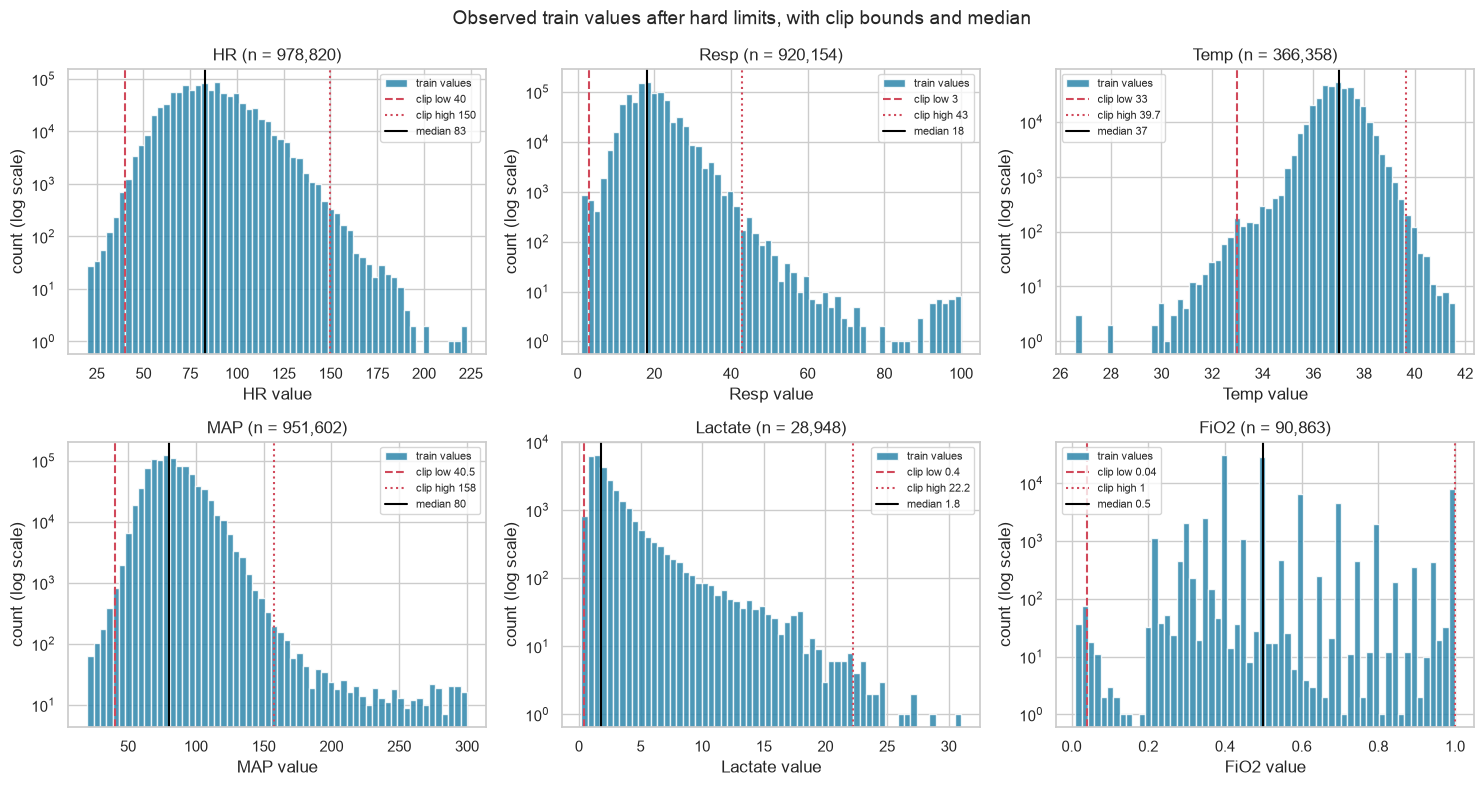

In [17]:
fig_cols = ["HR", "Resp", "Temp", "MAP", "Lactate", "FiO2"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), fig_cols):
    x = observed_values(master[c].to_numpy(dtype=np.float64)[train_master], c)
    lo, hi = params["clip"][c]
    ax.hist(x, bins=60, color=COLORS["non_septic"], alpha=0.85, label="train values")
    ax.axvline(lo, color=COLORS["septic"], ls="--", lw=1.5, label=f"clip low {lo:.3g}")
    ax.axvline(hi, color=COLORS["septic"], ls=":", lw=1.5, label=f"clip high {hi:.3g}")
    ax.axvline(params["median"][c], color="black", lw=1.5, label=f"median {params['median'][c]:.3g}")
    ax.set_yscale("log")
    ax.set_title(f"{c} (n = {len(x):,})")
    ax.set_xlabel(f"{c} value")
    ax.set_ylabel("count (log scale)")
    ax.legend(fontsize=8)
fig.suptitle("Observed train values after hard limits, with clip bounds and median", fontsize=14)
fig.tight_layout()
fig.savefig(FIGS / "fig04_clip_bounds.png", dpi=150)
plt.show()

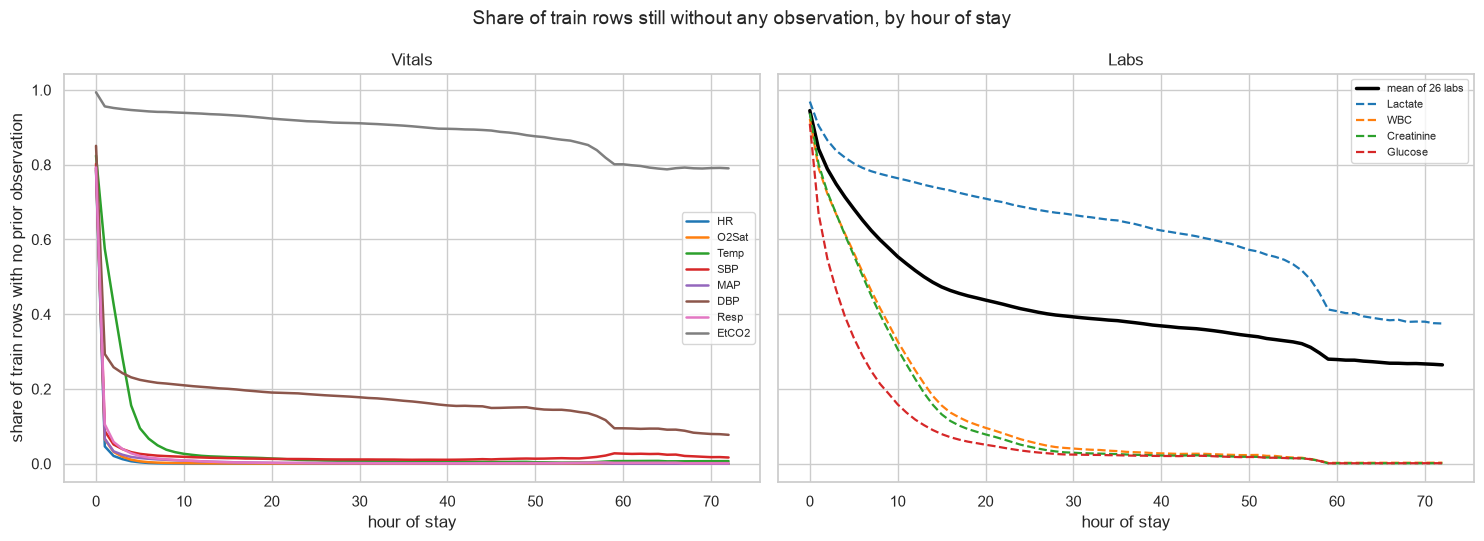

In [18]:
early = unscaled.loc[train_u & (unscaled["hour"] <= 72).to_numpy()]
by_hour = early[VALUE_COLS].isna().groupby(early["hour"].to_numpy()).mean()

fig, (ax_v, ax_l) = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for c, color in zip(VITALS, sns.color_palette("tab10", len(VITALS))):
    ax_v.plot(by_hour.index, by_hour[c], color=color, lw=1.8, label=c)
ax_v.set_title("Vitals")

ax_l.plot(by_hour.index, by_hour[LABS].mean(axis=1), color="black", lw=2.5, label=f"mean of {len(LABS)} labs")
for c, color in zip(["Lactate", "WBC", "Creatinine", "Glucose"], sns.color_palette("tab10", 4)):
    ax_l.plot(by_hour.index, by_hour[c], color=color, lw=1.6, ls="--", label=c)
ax_l.set_title("Labs")

for ax in (ax_v, ax_l):
    ax.set_xlabel("hour of stay")
    ax.legend(fontsize=8)
ax_v.set_ylabel("share of train rows with no prior observation")
fig.suptitle("Share of train rows still without any observation, by hour of stay", fontsize=14)
fig.tight_layout()
fig.savefig(FIGS / "fig04_never_observed_by_hour.png", dpi=150)
plt.show()

## Saved files

Checklist of outputs and the written summary.

In [19]:
failed = [label for label, ok in CHECKS if not ok]
log(f"checks: {len(CHECKS) - len(failed)} passed, {len(failed)} failed")
for label in failed:
    log(f"  failed: {label}")

saved = [
    PROC / "pre_unscaled.parquet",
    PROC / "pre_scaled.parquet",
    PROC / "preprocess_params.joblib",
    TABLES / "preprocess_params.csv",
    TABLES / "never_observed_share_train.csv",
    FIGS / "fig04_clip_bounds.png",
    FIGS / "fig04_never_observed_by_hour.png",
]
log("saved files:")
for path in saved:
    log(f"  {path.relative_to(ROOT)}  {path.stat().st_size / 1e6:.2f} MB")

summary_path = TABLES.parent / "step04_summary.txt"
summary_path.write_text("\n".join(SUMMARY) + "\n")
print(summary_path.relative_to(ROOT))

checks: 42 passed, 0 failed
saved files:
  data/processed/pre_unscaled.parquet  38.42 MB
  data/processed/pre_scaled.parquet  37.48 MB
  data/processed/preprocess_params.joblib  0.00 MB
  results/tables/preprocess_params.csv  0.00 MB
  results/tables/never_observed_share_train.csv  0.00 MB
  results/figures/fig04_clip_bounds.png  0.20 MB
  results/figures/fig04_never_observed_by_hour.png  0.17 MB
results/step04_summary.txt
